# Fundamentals of Data Science - Case Studies

## Libraries and Settings

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

os.makedirs('figures', exist_ok=True)
os.makedirs('outputs', exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif',
    'axes.edgecolor': 'black',
    'axes.labelcolor': 'black',
    'text.color': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
    'axes.titleweight': 'bold',
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'figure.dpi': 100,
})

def save_show(name):
    plt.tight_layout()
    plt.savefig('figures/' + name + '.png', dpi=200, facecolor='white')
    plt.show()

def plot_confusion(ax, cm, title):
    ax.imshow(cm, cmap='Greys', vmin=0, vmax=cm.max() * 1.6)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=13,
                    color='white' if cm[i, j] > cm.max() * 0.6 else 'black')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Predicted No', 'Predicted Yes'])
    ax.set_yticklabels(['Actual No', 'Actual Yes'])
    ax.set_title(title)

# Case Study 3: Logistic Regression on the Titanic Dataset

## 1. Data Exploration

In [2]:
titanic = pd.read_excel('data/titanic.xlsx')
display(titanic.head(10))
print(titanic.shape)
print(titanic.dtypes)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin              str
Embarked           str
dtype: object


In [3]:
display(titanic.describe())
print(titanic.isnull().sum())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.62
1    38.38
Name: count, dtype: float64


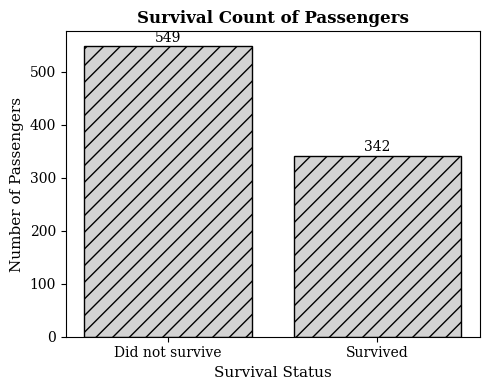

In [4]:
survival_counts = titanic['Survived'].value_counts().sort_index()
print(survival_counts)
print((survival_counts / len(titanic) * 100).round(2))

plt.figure(figsize=(5, 4))
bars = plt.bar(['Did not survive', 'Survived'], survival_counts.values, color='lightgrey', edgecolor='black', hatch='//')
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 8, int(b.get_height()), ha='center')
plt.title('Survival Count of Passengers')
plt.xlabel('Survival Status')
plt.ylabel('Number of Passengers')
save_show('cs3_survival_count')

Sex
female    74.20
male      18.89
Name: Survived, dtype: float64
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


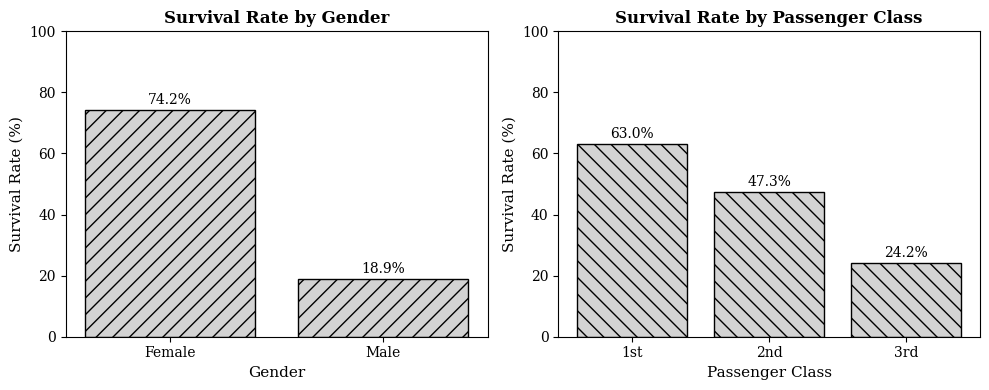

In [5]:
sex_rate = titanic.groupby('Sex')['Survived'].mean() * 100
class_rate = titanic.groupby('Pclass')['Survived'].mean() * 100
print(sex_rate.round(2))
print(class_rate.round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
b1 = axes[0].bar(sex_rate.index.str.title(), sex_rate.values, color='lightgrey', edgecolor='black', hatch='//')
axes[0].set_title('Survival Rate by Gender')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Survival Rate (%)')
b2 = axes[1].bar(['1st', '2nd', '3rd'], class_rate.values, color='lightgrey', edgecolor='black', hatch='\\\\')
axes[1].set_title('Survival Rate by Passenger Class')
axes[1].set_xlabel('Passenger Class')
axes[1].set_ylabel('Survival Rate (%)')
for ax, bars in zip(axes, [b1, b2]):
    ax.set_ylim(0, 100)
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 2, f'{b.get_height():.1f}%', ha='center')
save_show('cs3_survival_gender_class')

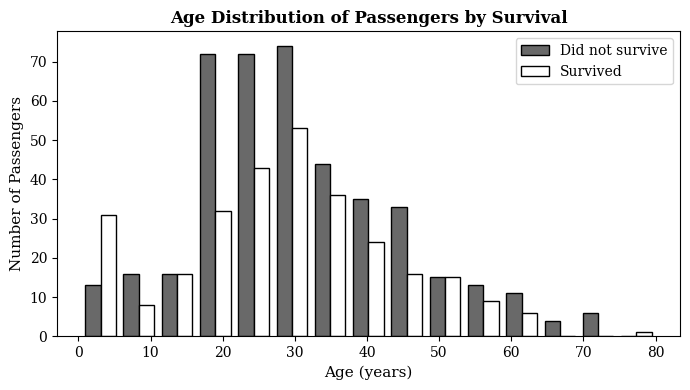

In [6]:
plt.figure(figsize=(7, 4))
plt.hist([titanic.loc[titanic['Survived'] == 0, 'Age'].dropna(),
          titanic.loc[titanic['Survived'] == 1, 'Age'].dropna()],
         bins=15, color=['dimgrey', 'white'], edgecolor='black', label=['Did not survive', 'Survived'])
plt.title('Age Distribution of Passengers by Survival')
plt.xlabel('Age (years)')
plt.ylabel('Number of Passengers')
plt.legend()
save_show('cs3_age_distribution')

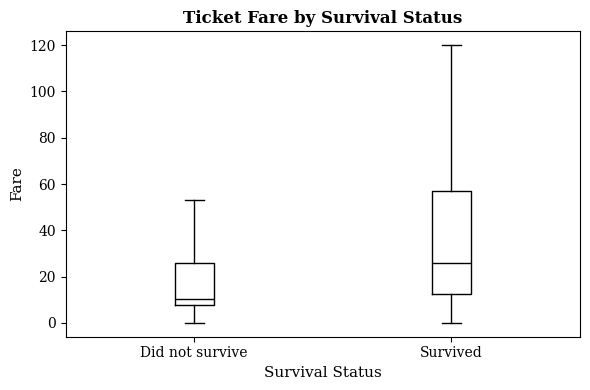

In [7]:
fare_groups = [titanic.loc[titanic['Survived'] == s, 'Fare'] for s in [0, 1]]
plt.figure(figsize=(6, 4))
plt.boxplot(fare_groups, tick_labels=['Did not survive', 'Survived'], showfliers=False,
            medianprops={'color': 'black'}, boxprops={'color': 'black'},
            whiskerprops={'color': 'black'}, capprops={'color': 'black'})
plt.title('Ticket Fare by Survival Status')
plt.xlabel('Survival Status')
plt.ylabel('Fare')
save_show('cs3_fare_boxplot')

          Survived  Pclass   Age  SibSp  Parch  Fare
Survived      1.00   -0.34 -0.08  -0.04   0.08  0.26
Pclass       -0.34    1.00 -0.37   0.08   0.02 -0.55
Age          -0.08   -0.37  1.00  -0.31  -0.19  0.10
SibSp        -0.04    0.08 -0.31   1.00   0.41  0.16
Parch         0.08    0.02 -0.19   0.41   1.00  0.22
Fare          0.26   -0.55  0.10   0.16   0.22  1.00


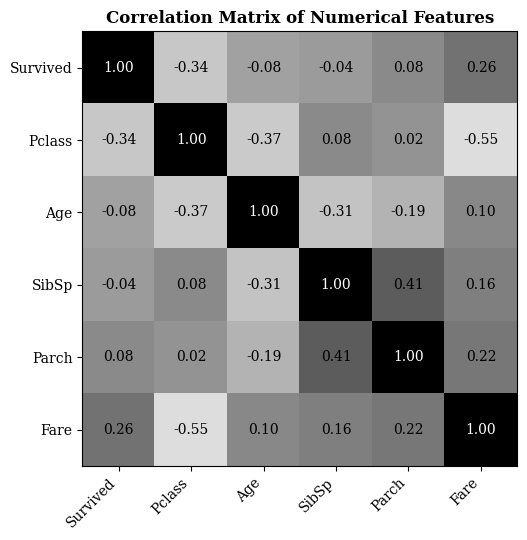

In [8]:
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr = titanic[numeric_cols].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(corr, cmap='Greys', vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_cols)))
ax.set_yticks(range(len(numeric_cols)))
ax.set_xticklabels(numeric_cols, rotation=45, ha='right')
ax.set_yticklabels(numeric_cols)
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', color='white' if abs(v) > 0.55 else 'black')
ax.set_title('Correlation Matrix of Numerical Features')
save_show('cs3_correlation')

## 2. Data Preprocessing

In [9]:
data = titanic.copy()
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])
data = data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])
data = pd.get_dummies(data, columns=['Sex', 'Embarked'], drop_first=True, dtype=int)
print(data.isnull().sum().sum())
display(data.head())

0


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


## 3. Model Building

In [10]:
X = data.drop(columns='Survived')
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

logit = LogisticRegression(max_iter=1000)
logit.fit(X_train, y_train)

(712, 8) (179, 8)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

## 4. Model Evaluation

In [11]:
pred = logit.predict(X_test)
prob = logit.predict_proba(X_test)[:, 1]

cs3_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Value': [accuracy_score(y_test, pred), precision_score(y_test, pred),
              recall_score(y_test, pred), f1_score(y_test, pred), roc_auc_score(y_test, prob)]
}).round(4)
display(cs3_metrics)
cs3_metrics.to_csv('outputs/cs3_metrics.csv', index=False)
print('Training accuracy:', round(logit.score(X_train, y_train), 4))
print(classification_report(y_test, pred))

,Metric,Value
0,Accuracy,0.8045
1,Precision,0.7931
2,Recall,0.6667
3,F1-Score,0.7244
4,ROC-AUC,0.8443


Training accuracy: 0.8076
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



[[98 12]
 [23 46]]


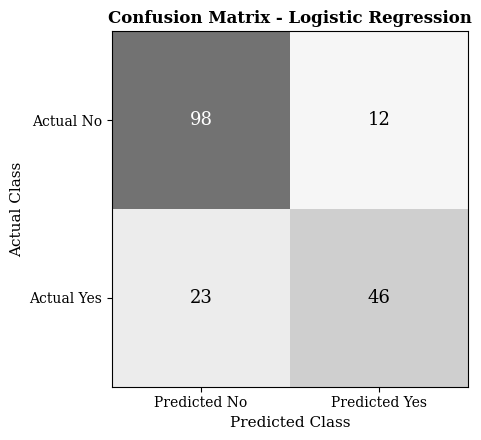

In [12]:
cm = confusion_matrix(y_test, pred)
print(cm)
fig, ax = plt.subplots(figsize=(5, 4.5))
plot_confusion(ax, cm, 'Confusion Matrix - Logistic Regression')
ax.set_xlabel('Predicted Class')
ax.set_ylabel('Actual Class')
save_show('cs3_confusion_matrix')
pd.DataFrame(cm, index=['Actual No', 'Actual Yes'], columns=['Predicted No', 'Predicted Yes']).to_csv('outputs/cs3_confusion.csv')

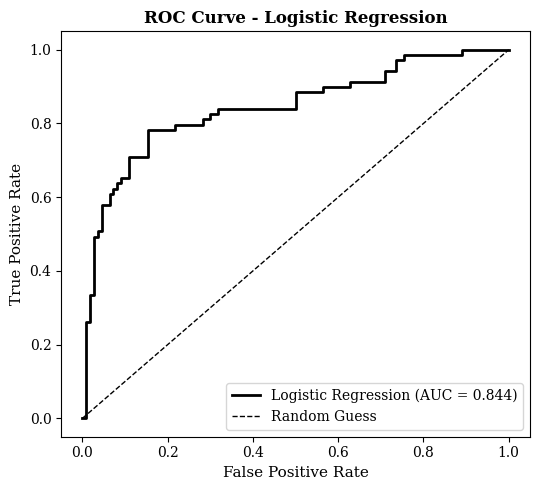

In [13]:
fpr, tpr, _ = roc_curve(y_test, prob)
plt.figure(figsize=(5.5, 5))
plt.plot(fpr, tpr, color='black', linewidth=2, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, prob):.3f})')
plt.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=1, label='Random Guess')
plt.title('ROC Curve - Logistic Regression')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
save_show('cs3_roc_curve')

## 5. Interpretation of Coefficients

,Feature,Coefficient,Odds Ratio
6,Embarked_Q,0.2812,1.3247
4,Fare,0.0022,1.0022
1,Age,-0.0385,0.9622
3,Parch,-0.0709,0.9316
2,SibSp,-0.2438,0.7836
7,Embarked_S,-0.3828,0.6819
0,Pclass,-1.0919,0.3356
5,Sex_male,-2.5579,0.0775


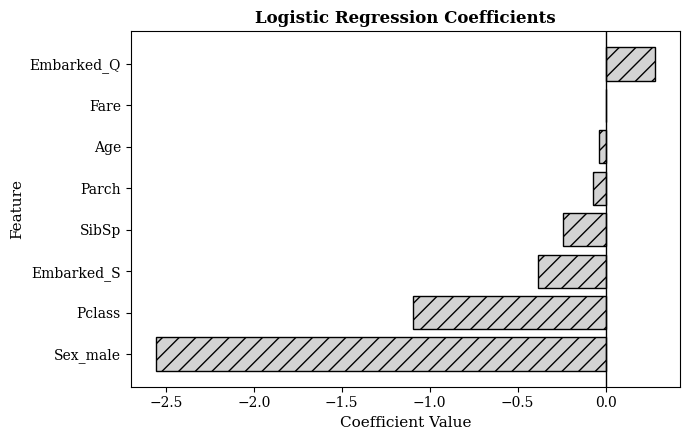

In [14]:
coef_table = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': logit.coef_[0],
    'Odds Ratio': np.exp(logit.coef_[0])
}).sort_values('Coefficient', ascending=False).round(4)
display(coef_table)
coef_table.to_csv('outputs/cs3_coefficients.csv', index=False)

ordered = coef_table.sort_values('Coefficient')
plt.figure(figsize=(7, 4.5))
plt.barh(ordered['Feature'], ordered['Coefficient'], color='lightgrey', edgecolor='black', hatch='//')
plt.axvline(0, color='black', linewidth=1)
plt.title('Logistic Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Feature')
save_show('cs3_coefficients')

## 6. Deployment with Streamlit

In [15]:
joblib.dump({'model': logit, 'columns': list(X.columns), 'age_median': float(titanic['Age'].median())}, 'titanic_model.pkl')

['titanic_model.pkl']

# Case Study 6: Bank Marketing Classification

## 1. Data Understanding and Preprocessing

In [16]:
bank = pd.read_csv('data/bank-full.csv', sep=';')
display(bank.head(10))
print(bank.shape)
print(bank.dtypes)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
5,35,management,married,tertiary,no,231,yes,no,unknown,5,may,139,1,-1,0,unknown,no
6,28,management,single,tertiary,no,447,yes,yes,unknown,5,may,217,1,-1,0,unknown,no
7,42,entrepreneur,divorced,tertiary,yes,2,yes,no,unknown,5,may,380,1,-1,0,unknown,no
8,58,retired,married,primary,no,121,yes,no,unknown,5,may,50,1,-1,0,unknown,no
9,43,technician,single,secondary,no,593,yes,no,unknown,5,may,55,1,-1,0,unknown,no


(45211, 17)
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


In [17]:
display(bank.describe())
numerical_cols = bank.select_dtypes(include='number').columns.tolist()
categorical_cols = bank.select_dtypes(exclude='number').columns.drop('y').tolist()
print('Numerical:', numerical_cols)
print('Categorical:', categorical_cols)
print('Target: y')

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Numerical: ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
Categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Target: y


In [18]:
print(bank.isnull().sum().sum())
unknown_counts = (bank[categorical_cols] == 'unknown').sum()
print(unknown_counts[unknown_counts > 0])
print((unknown_counts[unknown_counts > 0] / len(bank) * 100).round(2))
print('Duplicates:', bank.duplicated().sum())
print(bank['y'].value_counts())

0
job            288
education     1857
contact      13020
poutcome     36959
dtype: int64
job           0.64
education     4.11
contact      28.80
poutcome     81.75
dtype: float64
Duplicates: 0
y
no     39922
yes     5289
Name: count, dtype: int64


In [19]:
model_data = bank.drop(columns='duration').copy()
for col in ['default', 'housing', 'loan', 'y']:
    model_data[col] = (model_data[col] == 'yes').astype(int)
model_data = pd.get_dummies(model_data, columns=['job', 'marital', 'education', 'contact', 'month', 'poutcome'],
                            drop_first=True, dtype=int)
Xb = model_data.drop(columns='y')
yb = model_data['y']
print(Xb.shape)

Xb_train, Xb_test, yb_train, yb_test = train_test_split(Xb, yb, test_size=0.2, stratify=yb, random_state=42)

scale_cols = ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
scaler = StandardScaler()
Xb_train_s = Xb_train.copy()
Xb_test_s = Xb_test.copy()
Xb_train_s[scale_cols] = scaler.fit_transform(Xb_train[scale_cols])
Xb_test_s[scale_cols] = scaler.transform(Xb_test[scale_cols])
print(Xb_train_s.shape, Xb_test_s.shape)
print(yb_train.mean().round(4), yb_test.mean().round(4))

(45211, 41)


(36168, 41) (9043, 41)
0.117 0.117


## 2. Exploratory Data Analysis

     Count  Percentage
y                     
no   39922        88.3
yes   5289        11.7


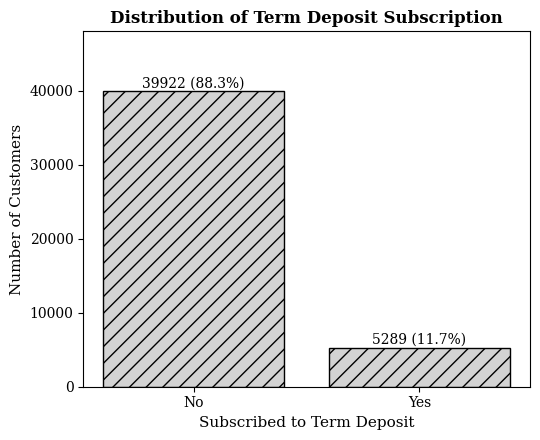

In [20]:
target_counts = bank['y'].value_counts()
target_pct = (target_counts / len(bank) * 100).round(2)
print(pd.DataFrame({'Count': target_counts, 'Percentage': target_pct}))

plt.figure(figsize=(5.5, 4.5))
bars = plt.bar(['No', 'Yes'], [target_counts['no'], target_counts['yes']], color='lightgrey', edgecolor='black', hatch='//')
for b, p in zip(bars, [target_pct['no'], target_pct['yes']]):
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 500, f'{int(b.get_height())} ({p}%)', ha='center')
plt.title('Distribution of Term Deposit Subscription')
plt.xlabel('Subscribed to Term Deposit')
plt.ylabel('Number of Customers')
plt.ylim(0, 48000)
save_show('cs6_target_distribution')

job
blue-collar       7.27
entrepreneur      8.27
housemaid         8.79
services          8.88
technician       11.06
unknown          11.81
self-employed    11.84
admin.           12.20
management       13.76
unemployed       15.50
retired          22.79
student          28.68
Name: y, dtype: float64


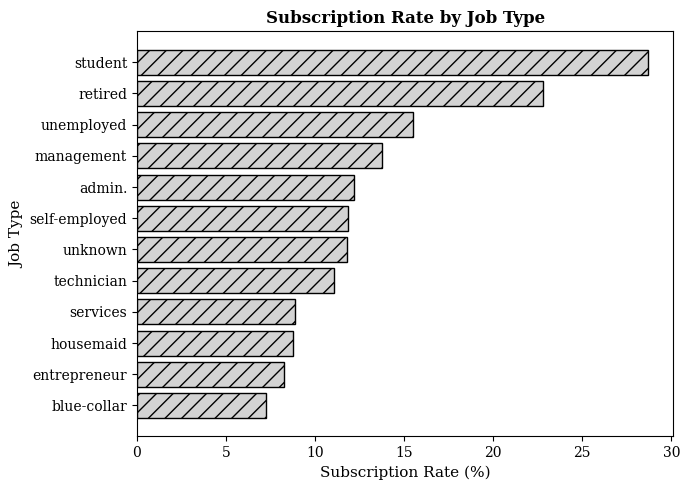

In [21]:
job_rate = (bank.groupby('job')['y'].apply(lambda s: (s == 'yes').mean() * 100)).sort_values()
print(job_rate.round(2))

plt.figure(figsize=(7, 5))
plt.barh(job_rate.index, job_rate.values, color='lightgrey', edgecolor='black', hatch='//')
plt.title('Subscription Rate by Job Type')
plt.xlabel('Subscription Rate (%)')
plt.ylabel('Job Type')
save_show('cs6_rate_by_job')

        Rate  Contacts
month                 
jan    10.12      1403
feb    16.65      2649
mar    51.99       477
apr    19.68      2932
may     6.72     13766
jun    10.22      5341
jul     9.09      6895
aug    11.01      6247
sep    46.46       579
oct    43.77       738
nov    10.15      3970
dec    46.73       214


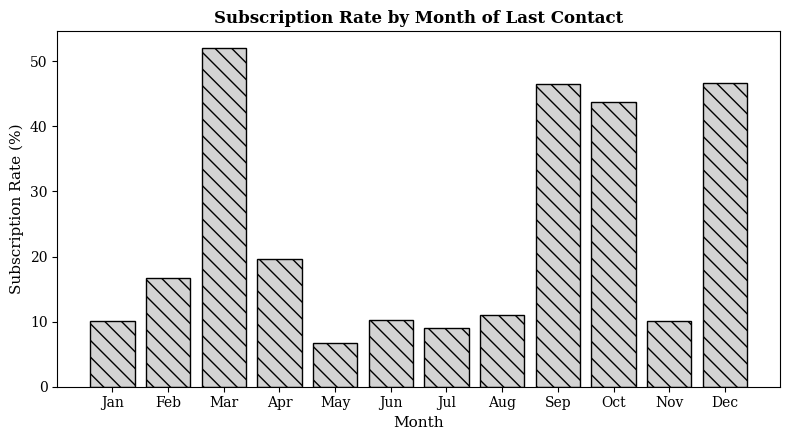

In [22]:
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
month_rate = bank.groupby('month')['y'].apply(lambda s: (s == 'yes').mean() * 100).reindex(month_order)
month_count = bank['month'].value_counts().reindex(month_order)
print(pd.DataFrame({'Rate': month_rate.round(2), 'Contacts': month_count}))

plt.figure(figsize=(8, 4.5))
plt.bar([m.title() for m in month_order], month_rate.values, color='lightgrey', edgecolor='black', hatch='\\\\')
plt.title('Subscription Rate by Month of Last Contact')
plt.xlabel('Month')
plt.ylabel('Subscription Rate (%)')
save_show('cs6_rate_by_month')

poutcome
unknown     9.16
failure    12.61
other      16.68
success    64.73
Name: y, dtype: float64


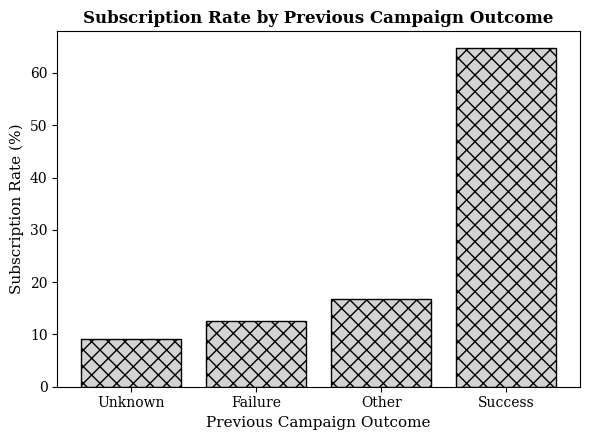

In [23]:
pout_rate = bank.groupby('poutcome')['y'].apply(lambda s: (s == 'yes').mean() * 100).sort_values()
print(pout_rate.round(2))

plt.figure(figsize=(6, 4.5))
plt.bar([p.title() for p in pout_rate.index], pout_rate.values, color='lightgrey', edgecolor='black', hatch='xx')
plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
save_show('cs6_rate_by_poutcome')

      age  balance  campaign  previous
y                                     
no   39.0    417.0       2.0       0.0
yes  38.0    733.0       2.0       0.0


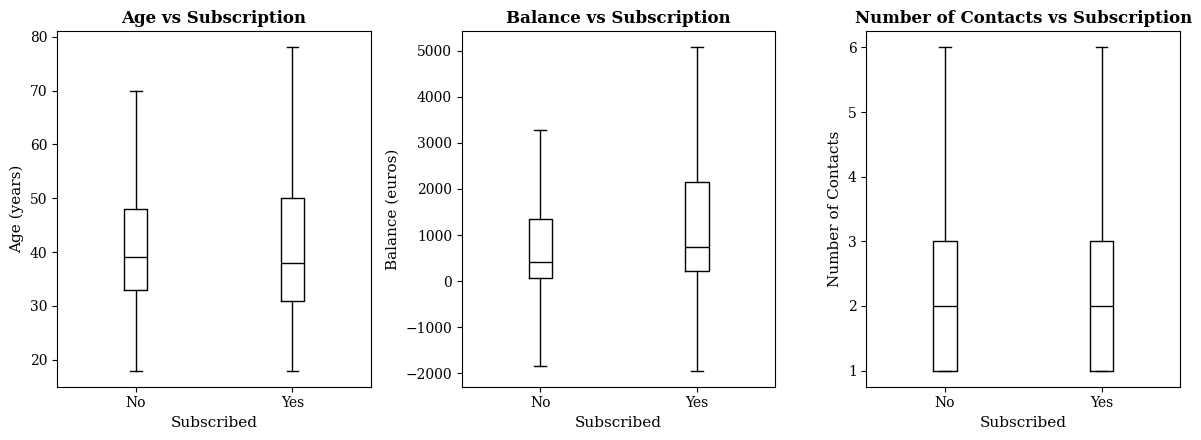

In [24]:
print(bank.groupby('y')[['age', 'balance', 'campaign', 'previous']].median())

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
for ax, col, label in zip(axes, ['age', 'balance', 'campaign'], ['Age (years)', 'Balance (euros)', 'Number of Contacts']):
    ax.boxplot([bank.loc[bank['y'] == 'no', col], bank.loc[bank['y'] == 'yes', col]],
               tick_labels=['No', 'Yes'], showfliers=False,
               medianprops={'color': 'black'}, boxprops={'color': 'black'},
               whiskerprops={'color': 'black'}, capprops={'color': 'black'})
    ax.set_title(label.split(' (')[0] + ' vs Subscription')
    ax.set_xlabel('Subscribed')
    ax.set_ylabel(label)
save_show('cs6_numeric_boxplots')

## 3. Classification Model Development

In [25]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1),
}

rows = []
predictions = {}
probabilities = {}
matrices = {}
for name, model in models.items():
    model.fit(Xb_train_s, yb_train)
    pred_b = model.predict(Xb_test_s)
    prob_b = model.predict_proba(Xb_test_s)[:, 1]
    predictions[name] = pred_b
    probabilities[name] = prob_b
    matrices[name] = confusion_matrix(yb_test, pred_b)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(yb_test, pred_b),
        'Precision': precision_score(yb_test, pred_b, zero_division=0),
        'Recall': recall_score(yb_test, pred_b),
        'F1-Score': f1_score(yb_test, pred_b),
        'ROC-AUC': roc_auc_score(yb_test, prob_b),
    })

results = pd.DataFrame(rows).set_index('Model').round(4)
display(results)
results.to_csv('outputs/cs6_metrics.csv')

,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8933,0.6655,0.1767,0.2793,0.7717
Decision Tree,0.8925,0.6396,0.1862,0.2884,0.7122
KNN,0.8873,0.5520,0.1957,0.2889,0.7045
Random Forest,0.8946,0.6937,0.1777,0.2829,0.7978


## 4. Model Performance Comparison and Visualization

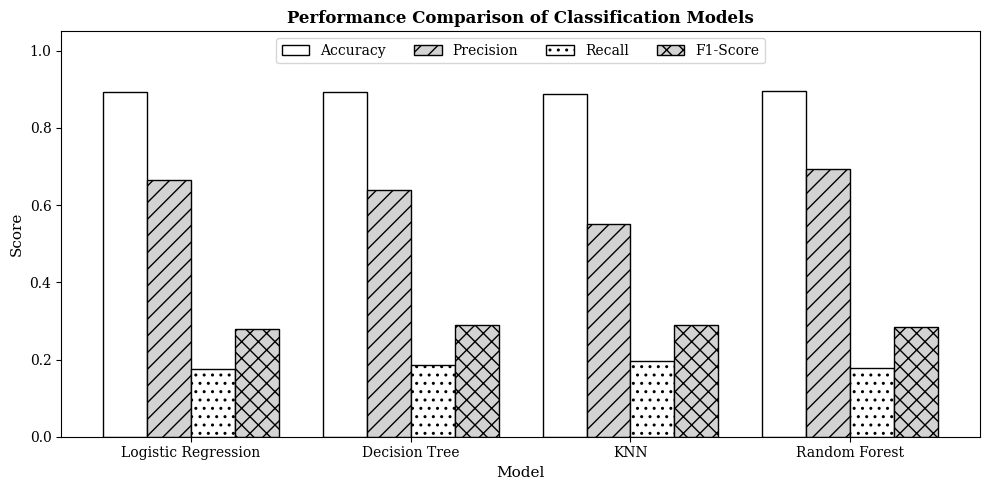

In [26]:
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
patterns = ['', '//', '..', 'xx']
x = np.arange(len(results))
width = 0.2

plt.figure(figsize=(10, 5))
for i, (metric, pattern) in enumerate(zip(metric_names, patterns)):
    plt.bar(x + (i - 1.5) * width, results[metric], width, label=metric,
            color='white' if i % 2 == 0 else 'lightgrey', edgecolor='black', hatch=pattern)
plt.xticks(x, results.index)
plt.ylim(0, 1.05)
plt.title('Performance Comparison of Classification Models')
plt.xlabel('Model')
plt.ylabel('Score')
plt.legend(loc='upper center', ncol=4)
save_show('cs6_model_comparison')

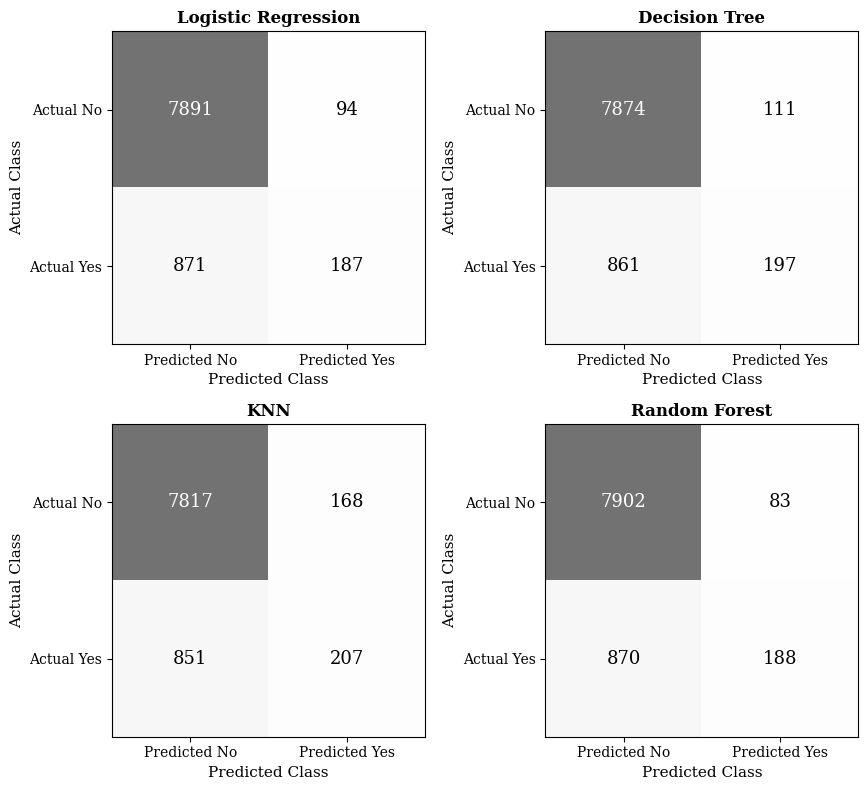

                       TN   FP   FN   TP
Logistic Regression  7891   94  871  187
Decision Tree        7874  111  861  197
KNN                  7817  168  851  207
Random Forest        7902   83  870  188


In [27]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (name, cm_b) in zip(axes.ravel(), matrices.items()):
    plot_confusion(ax, cm_b, name)
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('Actual Class')
save_show('cs6_confusion_matrices')
pd.DataFrame({name: m.ravel() for name, m in matrices.items()}, index=['TN', 'FP', 'FN', 'TP']).T.to_csv('outputs/cs6_confusion.csv')
print(pd.DataFrame({name: m.ravel() for name, m in matrices.items()}, index=['TN', 'FP', 'FN', 'TP']).T)

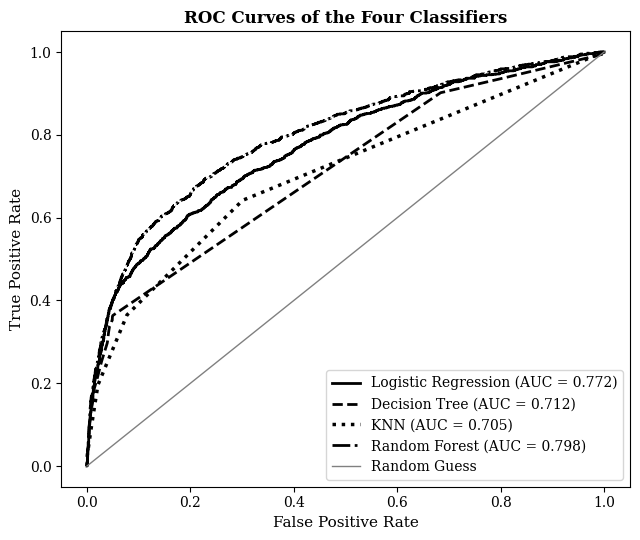

In [28]:
styles = {'Logistic Regression': '-', 'Decision Tree': '--', 'KNN': ':', 'Random Forest': '-.'}
widths = {'Logistic Regression': 2, 'Decision Tree': 2, 'KNN': 2.5, 'Random Forest': 2}
plt.figure(figsize=(6.5, 5.5))
for name in models:
    fpr_b, tpr_b, _ = roc_curve(yb_test, probabilities[name])
    plt.plot(fpr_b, tpr_b, color='black', linestyle=styles[name], linewidth=widths[name],
             label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], color='grey', linewidth=1, label='Random Guess')
plt.title('ROC Curves of the Four Classifiers')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
save_show('cs6_roc_curves')

## 5. Interpretation and Business Recommendations

Best model: Random Forest
              precision    recall  f1-score   support

          No       0.90      0.99      0.94      7985
         Yes       0.69      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.80      0.58      0.61      9043
weighted avg       0.88      0.89      0.87      9043



poutcome_success    0.1956
age                 0.1022
pdays               0.0862
balance             0.0780
day                 0.0708
housing             0.0489
previous            0.0420
month_mar           0.0342
contact_unknown     0.0339
campaign            0.0328
dtype: float64

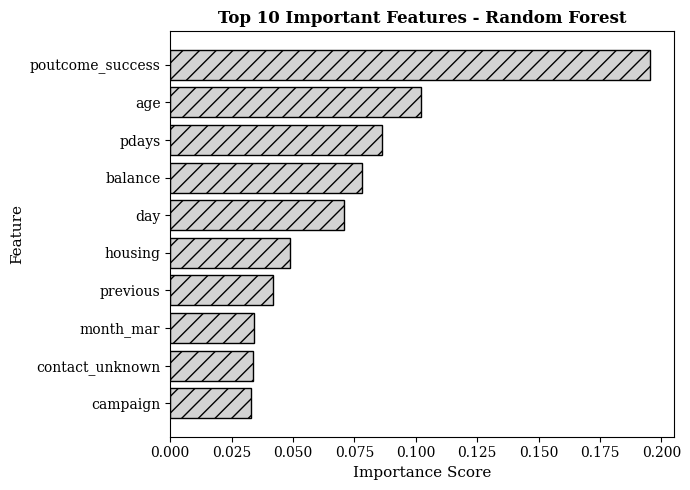

In [29]:
best_model = results['ROC-AUC'].idxmax()
print('Best model:', best_model)
print(classification_report(yb_test, predictions[best_model], target_names=['No', 'Yes']))

importance = pd.Series(models[best_model].feature_importances_, index=Xb_train_s.columns).sort_values(ascending=False).head(10)
display(importance.round(4))
importance.round(4).to_csv('outputs/cs6_importance.csv', header=['Importance'])

plt.figure(figsize=(7, 5))
plt.barh(importance.index[::-1], importance.values[::-1], color='lightgrey', edgecolor='black', hatch='//')
plt.title('Top 10 Important Features - ' + best_model)
plt.xlabel('Importance Score')
plt.ylabel('Feature')
save_show('cs6_feature_importance')

In [30]:
ranking = pd.DataFrame({'actual': yb_test.values, 'score': probabilities[best_model]}).sort_values('score', ascending=False).reset_index(drop=True)
total_yes = ranking['actual'].sum()
gain_rows = []
for share in [0.10, 0.20, 0.30, 0.50]:
    top = ranking.head(int(len(ranking) * share))
    gain_rows.append({
        'Customers Contacted (%)': int(share * 100),
        'Subscribers Found': int(top['actual'].sum()),
        'Share of All Subscribers (%)': round(top['actual'].sum() / total_yes * 100, 2),
        'Subscription Rate (%)': round(top['actual'].mean() * 100, 2),
    })
gain = pd.DataFrame(gain_rows)
display(gain)
gain.to_csv('outputs/cs6_gain.csv', index=False)

,Customers Contacted (%),Subscribers Found,Share of All Subscribers (%),Subscription Rate (%)
0,10,449,42.44,49.67
1,20,639,60.40,35.34
2,30,748,70.70,27.58
3,50,881,83.27,19.49
